# Chapter 25: Multitask, Team, Career-Concern, and Robust Contracts

This notebook reruns four worked examples from the chapter: career-concern effort, the multitask problem, the optimal slope of a linear contract under noise, and the ratchet effect. Every example is hypothetical, as in the book; a few extra input values are added for comparison.

## Setup

The functions below are the calculations behind every number in this notebook. Run this cell first.

In [1]:
import math
from types import SimpleNamespace

import numpy as np
import matplotlib
import matplotlib.pyplot as plt



PALETTE = {
    "ink": "#172a3b",
    "teal": "#136f75",
    "gold": "#8f5d0f",
    "navy": "#334c72",
    "terracotta": "#a24a33",
    "olive": "#5d6a37",
    "grey": "#6b757b",
    "light": "#c9d3d6",
}


CYCLE = ["teal", "navy", "gold", "terracotta", "olive", "grey"]


LABEL_SIZE = 10.5


HOUSE_RC = {
    "font.size": 11.5,
    "axes.titlesize": 12,
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#6b757b",
    "axes.labelcolor": "#172a3b",
    "xtick.color": "#172a3b",
    "ytick.color": "#172a3b",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "svg.fonttype": "path",
}


def color(name_or_index):
    """Palette colour by name ('teal') or by position in the series cycle (0, 1, ...)."""
    if isinstance(name_or_index, int):
        return PALETTE[CYCLE[name_or_index % len(CYCLE)]]
    return PALETTE.get(name_or_index, name_or_index)


def tex_safe(text):
    """Escape dollar signs so Matplotlib does not read '$...$' as mathematics."""
    return str(text).replace("\\$", "$").replace("$", r"\$")


def new_figure(ncols=1, width=None, height=4.3):
    """Notebook twin of readerkit.new_figure: one panel 6.6 x 4.3 in, two panels 10.4 x 4.3 in."""
    import matplotlib.pyplot as plt

    if width is None:
        width = 6.6 if ncols == 1 else 10.4
    fig, axes = plt.subplots(1, ncols, figsize=(width, height), layout="constrained")
    for ax in (axes if ncols > 1 else [axes]):
        ax.grid(alpha=0.18)
    return fig, axes


def label(ax, x, y, text, col="ink", dx=6, dy=6, ha="left", va="bottom", box=True, size=LABEL_SIZE):
    """Direct label at data point (x, y) offset by (dx, dy) points, with a white box by default."""
    kw = {}
    if box:
        kw["bbox"] = {"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9}
    return ax.annotate(tex_safe(text), (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va,
                       color=color(col), fontsize=size, **kw)


def mark(ax, x, y, text=None, col="ink", size=42, dx=6, dy=6, ha="left", va="bottom", zorder=5):
    """Filled point with an optional direct label."""
    ax.scatter([x], [y], s=size, color=color(col), zorder=zorder)
    if text:
        label(ax, x, y, text, col=col, dx=dx, dy=dy, ha=ha, va=va)


def vline(ax, x, text=None, col="grey", style="dashed", y_frac=0.95, ha="left", lw=1.4):
    """Vertical reference line with an optional label near the top of the axes."""
    ax.axvline(x, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x, y_frac), xycoords=("data", "axes fraction"), xytext=(5 if ha == "left" else -5, 0),
                    textcoords="offset points", ha=ha, va="top", color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def bar_compare(ax, names, values, colors=None, value_labels=None, ylabel="Value", xlabel="Item", fmt=None,
                zero_line=True):
    """Labelled vertical bars, one per name; each bar carries its value label.

    ``value_labels`` gives the text over each bar (else ``fmt(v)`` or '{:,.2f}').
    Negative bars are allowed; labels go below them.
    """
    values = [float(v) for v in values]
    colors = colors or [color(i) for i in range(len(values))]
    xs = np.arange(len(values))
    ax.bar(xs, values, color=[color(c) for c in colors], width=0.6)
    ax.set_xticks(xs, names)
    lo, hi = min(0.0, min(values)), max(0.0, max(values))
    span = (hi - lo) or 1.0
    ax.set_ylim(lo - (0.14 * span if lo < 0 else 0), hi + 0.16 * span)
    for x, v, i in zip(xs, values, range(len(values))):
        text = value_labels[i] if value_labels else (fmt(v) if fmt else f"{v:,.2f}")
        ax.annotate(text, (x, v), xytext=(0, 4 if v >= 0 else -4), textcoords="offset points", ha="center",
                    va="bottom" if v >= 0 else "top", fontsize=LABEL_SIZE, color=PALETTE["ink"])
    if zero_line and lo < 0:
        ax.axhline(0, color=PALETTE["grey"], linewidth=1)
    ax.set_ylabel(ylabel)
    ax.set_xlabel(xlabel)
    return ax


def stacked_bar(ax, names, parts, part_labels, colors=None, ylabel="Value", total_marker=True, fmt=None):
    """Bars built from signed parts (one list per part), with a marker at each bar's net total.

    Positive parts stack upward from zero and negative parts downward, so a bar with a
    negative substitution part and a positive income part shows both pieces and the net.
    """
    parts = [[float(v) for v in p] for p in parts]
    n = len(names)
    xs = np.arange(n)
    colors = colors or [color(i) for i in range(len(parts))]
    pos_base, neg_base = np.zeros(n), np.zeros(n)
    for p, lab, col in zip(parts, part_labels, colors):
        p = np.array(p)
        base = np.where(p >= 0, pos_base, neg_base)
        ax.bar(xs, p, bottom=base, color=color(col), width=0.55, label=lab)
        pos_base = pos_base + np.where(p >= 0, p, 0)
        neg_base = neg_base + np.where(p < 0, p, 0)
    totals = np.sum(np.array(parts), axis=0)
    if total_marker:
        ax.scatter(xs, totals, marker="D", s=46, color=PALETTE["ink"], zorder=5)
        for x, t in zip(xs, totals):
            ax.annotate(f"net {fmt(t) if fmt else f'{t:,.2f}'}", (x, t), xytext=(14, 0), textcoords="offset points",
                        ha="left", va="center", fontsize=LABEL_SIZE,
                        bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})
    ax.axhline(0, color=PALETTE["grey"], linewidth=1)
    ax.set_xticks(xs, names)
    ax.set_xlim(-0.6, n - 0.4 + 0.5)
    ax.set_ylabel(ylabel)
    return ax


def num(value, digits=2, comma=True):
    """Fixed-decimal string with optional thousands separators: num(1444.444) -> '1,444.44'.

    Negative zero prints as '0'. Raises ValueError on NaN or infinity, because an
    undefined value must be named in words (see ``undefined``).
    """
    value = float(value)
    if not math.isfinite(value):
        raise ValueError("non-finite value; name it with undefined(reason)")
    text = f"{value:,.{digits}f}" if comma else f"{value:.{digits}f}"
    if text.startswith("-") and float(text.replace(",", "")) == 0:
        text = text[1:]
    return text


def career_concerns_effort(var_theta, var_eps=1.0, delta=0.9):
    """career-concerns-incentives (EP-105): beta = var_theta/(var_theta + var_eps), e* = delta beta, cost e*^2/2.

    Book (ch025): variance 1 gives beta 0.5, e* 0.45, cost 0.10125; variance 1/3 gives beta 0.25, e* 0.225.
    """
    beta = var_theta / (var_theta + var_eps)
    e = delta * beta
    return {"beta": beta, "effort": e, "cost": e * e / 2}


def multitask_efforts(b, by=4.0, rho=0.5):
    """multitask-incentive-problem (EP-147): maximize b x + by y - (x^2 + y^2)/2 - rho x y.

    First-order conditions x + rho y = b, y + rho x = by give x = (b - rho by)/(1 - rho^2), y = by - rho x,
    floored at zero. Book (ch025): b 4, rho 0.5 gives x = y = 8/3; b 7 gives 20/3 and 2/3; rho 0 gives x = b, y = 4.
    """
    x = (b - rho * by) / (1 - rho * rho)
    y = by - rho * x
    if y < 0:
        y, x = 0.0, b
    if x < 0:
        x, y = 0.0, by
    return {"x": x, "y": y}


def multitask_value(x, y, vx=2.0, vy=10.0):
    """multitask-incentive-problem (EP-147): gross value vx x + vy y. Book (ch025): 32, 20, 48, 54."""
    return vx * x + vy * y


def linear_contract_slope(r, var):
    """linear-contract-robustness (EP-139): b* = 1 / (1 + r var) with c(e) = e^2/2 and e = b.

    Book (ch025): r 0.05, var 16 gives 0.556; var 4 gives 0.833.
    """
    return 1.0 / (1.0 + r * var)


def linear_contract_surplus(b, r, var):
    """linear-contract-robustness (EP-139): S(b) = b - b^2/2 - (1/2) r var b^2, with its parts.

    Book (ch025): b* 0.5556 gives effort cost 0.1543, risk premium 0.1235, surplus 0.2778.
    """
    cost = 0.5 * b * b
    premium = 0.5 * r * var * b * b
    return {"output": b, "effort_cost": cost, "risk_premium": premium, "surplus": b - cost - premium}


def ratchet_payoffs(now_r, now_c, cont_r, cont_c, delta):
    """ratchet-effect (EP-157): reveal = now_r + delta cont_r, conceal = now_c + delta cont_c.

    Book (ch025): 15 + 0.9(4) = 18.6 against 5 + 0.9(20) = 23 (conceal); with commitment 15 + 0.9(20) = 33.
    Indifference at delta = (now_r - now_c)/(cont_c - cont_r) when cont_c > cont_r (0.625 in the book case).
    """
    reveal = now_r + delta * cont_r
    conceal = now_c + delta * cont_c
    if abs(reveal - conceal) < 1e-9:
        choice = "tie"
    else:
        choice = "reveal" if reveal > conceal else "conceal"
    threshold = (now_r - now_c) / (cont_c - cont_r) if cont_c > cont_r else None
    return {"reveal": reveal, "conceal": conceal, "choice": choice, "threshold": threshold}


plt.rcParams.update(HOUSE_RC)


information = SimpleNamespace(career_concerns_effort=career_concerns_effort, multitask_efforts=multitask_efforts, multitask_value=multitask_value, linear_contract_slope=linear_contract_slope, linear_contract_surplus=linear_contract_surplus, ratchet_payoffs=ratchet_payoffs)


# The book's printed values for this chapter (inputs of the worked examples).
BV = {'career-concerns-incentives': {'var_theta': 1,
                                'var_eps': 1,
                                'delta': 0.9,
                                'beta': 0.5,
                                'effort': 0.45,
                                'cost': 0.10125,
                                'var_theta_2': 0.3333333333333333,
                                'beta_2': 0.25,
                                'effort_2': 0.225},
 'multitask-incentive-problem': {'b': 4,
                                 'by': 4,
                                 'rho': 0.5,
                                 'vx': 2,
                                 'vy': 10,
                                 'x': 2.6666666666666665,
                                 'y': 2.6666666666666665,
                                 'value': 32,
                                 'b_2': 7,
                                 'x_2': 6.666666666666667,
                                 'y_2': 0.6666666666666666,
                                 'value_2': 20,
                                 'value_rho0': 48,
                                 'value_rho0_2': 54},
 'linear-contract-robustness': {'var': 16,
                                'r': 0.05,
                                'b_star': 0.556,
                                'effort_cost': 0.154,
                                'risk_premium': 0.123,
                                'surplus_printed_as': 0.279,
                                'surplus_exact_3dp': 0.278,
                                'var_2': 4,
                                'b_star_2': 0.833},
 'ratchet-effect': {'now_r': 15,
                    'now_c': 5,
                    'cont_r': 4,
                    'cont_c': 20,
                    'delta': 0.9,
                    'reveal': 18.6,
                    'conceal': 23,
                    'reveal_commit': 33},
 'constructed': {'career-concerns-incentives': {'var_thetas': [0.3333333333333333, 1, 3],
                                                'deltas': [0.8, 0.9, 1.0]},
                 'multitask-incentive-problem': {'bs': [4, 5, 6, 7]},
                 'linear-contract-robustness': {'vars': [4, 16, 36], 'rs': [0.01, 0.05, 0.1]},
                 'ratchet-effect': {'deltas': [0.5, 0.6, 0.9], 'threshold': 0.625}}}


def frac(v):
    """1/3 shown as a fraction, other values as plain numbers."""
    return "1/3" if abs(v - 1 / 3) < 1e-12 else num(v, 0)


def finish(interp, steps):
    return interp + " Hand check: " + "; ".join(steps) + "."


def career_picture(var_theta=1.0, delta=0.9):
    r = information.career_concerns_effort(var_theta, 1.0, delta)
    beta, e, cost = r["beta"], r["effort"], r["cost"]
    fig, ax = new_figure()
    bar_compare(ax, ["Weight on output beta", "Effort e*", "Effort cost"], [beta, e, cost],
                colors=["navy", "teal", "terracotta"], value_labels=[num(beta, 4), num(e, 4), num(cost, 5)],
                ylabel="Value", xlabel=f"Ability variance {frac(var_theta)}, discount factor {num(delta, 1)}")
    ax.set_ylim(0, 1.0)
    metrics = {"Posterior weight beta": num(beta, 4), "Effort e*": num(e, 4), "Effort cost": num(cost, 5)}
    steps = [f"beta = {frac(var_theta)} / ({frac(var_theta)} + 1) = {num(beta, 4)}",
             f"e* = {num(delta, 1)} x {num(beta, 4)} = {num(e, 4)}",
             f"Cost = {num(e, 4)} x {num(e, 4)} / 2 = {num(cost, 5)}"]
    interp = (f"The market puts weight {num(beta, 4)} on Elena's output when it updates its view of her ability, so "
              f"one more unit of effort raises discounted future pay by {num(e, 4)}. With cost e^2/2 she sets effort "
              f"equal to that return: e* = {num(e, 4)}, at a cost of {num(cost, 5)}, with no current bonus at all.")
    alt = (f"Bars for the posterior weight {num(beta, 4)}, effort {num(e, 4)} and effort cost {num(cost, 5)} at "
           f"ability variance {frac(var_theta)} and discount factor {num(delta, 1)}.")
    return fig, metrics, finish(interp, steps), {"alt": alt, "steps": steps}


def multitask_picture(b=4, rho=0.5):
    r = information.multitask_efforts(b, 4.0, rho)
    x, y = r["x"], r["y"]
    value = information.multitask_value(x, y, 2, 10)
    base = information.multitask_efforts(4, 4.0, rho)
    base_value = information.multitask_value(base["x"], base["y"], 2, 10)
    fig, ax = new_figure()
    bar_compare(ax, ["Closure effort x", "Diagnostic effort y"], [x, y], colors=["teal", "navy"],
                value_labels=[num(x), num(y)], ylabel="Effort",
                xlabel=f"Gross value 2x + 10y = {num(value)}")
    ax.set_ylim(0, 8.5)
    metrics = {"Closure effort x": num(x), "Diagnostic effort y": num(y), "Gross value": num(value),
               "Change from b = 4": num(value - base_value)}
    if rho == 0:
        steps = [f"With rho = 0: x = b = {num(x, 4)} and y = 4"]
    else:
        steps = [f"x = ({num(b, 0)} - 0.5 x 4) / (1 - 0.25) = {num(b - 2, 0)} / 0.75 = {num(x, 4)}",
                 f"y = 4 - 0.5 x {num(x, 4)} = {num(y, 4)}"]
    steps.append(f"Value = 2 x {num(x, 4)} + 10 x {num(y, 4)} = {num(2 * x)} + {num(10 * y)} = {num(value)}")
    if b == 4:
        move = "This is the starting incentive b = 4."
    elif value > base_value:
        move = f"Raising b from 4 to {num(b, 0)} adds {num(value - base_value)} of value, because the tasks do not compete."
    else:
        move = (f"Raising b from 4 to {num(b, 0)} cuts value by {num(base_value - value)}: the extra closures crowd "
                f"out diagnostic work worth 10 a unit.")
    interp = (f"With closure incentive {num(b, 0)} and cross-task parameter {num(rho, 1)}, the agent closes "
              f"{num(x)} units and diagnoses {num(y)}, for gross value {num(value)}. {move}")
    alt = (f"Bars for closure effort {num(x)} and diagnostic effort {num(y)}; gross value {num(value)} at b = "
           f"{num(b, 0)} and rho = {num(rho, 1)}.")
    return fig, metrics, finish(interp, steps), {"alt": alt, "steps": steps}


def slope_picture(var=16, r=0.05):
    bstar = information.linear_contract_slope(r, var)
    s = information.linear_contract_surplus(bstar, r, var)
    k = 0.5 + 0.5 * r * var
    fig, ax = new_figure()
    grid = np.linspace(0, 1, 201)
    ax.plot(grid, [information.linear_contract_surplus(g, r, var)["surplus"] for g in grid], color=PALETTE["teal"],
            linewidth=2.2)
    mark(ax, bstar, s["surplus"], f"b* = {num(bstar, 3)}, S = {num(s['surplus'], 3)}", col="terracotta",
         dx=8 if bstar < 0.7 else -8, dy=8, ha="left" if bstar < 0.7 else "right")
    # label sits away from the curve: low when S(1) is high, high when the curve ends far below zero
    vline(ax, 1.0, "risk-neutral limit b = 1", col="grey", ha="right", y_frac=0.12 if 1 - k >= 0 else 0.95)
    ax.set_xlim(0, 1.05)
    ax.set_ylim(-1.4, 0.7)
    ax.axhline(0, color=PALETTE["grey"], linewidth=1)
    ax.set_xlabel("Commission slope b")
    ax.set_ylabel("Surplus S(b)")
    metrics = {"Optimal slope b*": num(bstar, 3), "Effort cost": num(s["effort_cost"], 3),
               "Risk premium": num(s["risk_premium"], 3), "Surplus": num(s["surplus"], 3)}
    steps = [f"S(b) = b - 0.5b^2 - 0.5 x {num(r, 2)} x {num(var, 0)} b^2 = b - {num(k, 4)}b^2",
             f"b* = 1 / (2 x {num(k, 4)}) = {num(bstar, 4)}",
             f"Effort cost = 0.5 x {num(bstar, 5)}^2 = {num(s['effort_cost'], 4)}",
             f"Risk premium = 0.5 x {num(r, 2)} x {num(var, 0)} x {num(bstar, 5)}^2 = {num(s['risk_premium'], 4)}",
             f"Surplus = b*/2 = {num(bstar, 4)} / 2 = {num(s['surplus'], 4)}"]
    interp = (f"With residual variance {num(var, 0)} and risk aversion {num(r, 2)}, the risk premium is "
              f"0.5 x {num(r * var, 2)} x b^2, so the best slope is {num(bstar, 3)}, below the risk-neutral "
              f"slope of 1. Effort costs {num(s['effort_cost'], 3)}, the risk premium is "
              f"{num(s['risk_premium'], 3)} and surplus is {num(s['surplus'], 3)}.")
    alt = (f"The surplus curve S(b) on slopes from 0 to 1, peaking at b* = {num(bstar, 3)} with surplus "
           f"{num(s['surplus'], 3)}, and a reference line at b = 1.")
    return fig, metrics, finish(interp, steps), {"alt": alt, "steps": steps}


def ratchet_picture(delta=0.9, commit="no"):
    b = BV["ratchet-effect"]
    cont_r = b["cont_c"] if commit == "yes" else b["cont_r"]
    r = information.ratchet_payoffs(b["now_r"], b["now_c"], cont_r, b["cont_c"], delta)
    fig, ax = new_figure()
    stacked_bar(ax, ["Reveal (deliver 100)", "Conceal (deliver 80)"],
                [[b["now_r"], b["now_c"]], [delta * cont_r, delta * b["cont_c"]]],
                ["payoff now", "discounted future"], colors=["navy", "teal"], ylabel="Total payoff",
                fmt=lambda v: num(v))
    ax.legend(loc="upper left", frameon=False)
    ax.set_xlabel("Buyer can commit" if commit == "yes" else "Buyer cannot commit")
    ax.set_ylim(0, 45)
    choice = r["choice"]
    metrics = {"Reveal": num(r["reveal"]), "Conceal": num(r["conceal"]),
               "Choice": "tie" if choice == "tie" else choice}
    steps = [f"Reveal = 15 + {num(delta, 1)} x {num(cont_r, 0)} = {num(r['reveal'])}",
             f"Conceal = 5 + {num(delta, 1)} x 20 = {num(r['conceal'])}"]
    if commit == "yes":
        tail = "With commitment the future payoff no longer depends on what the buyer sees, so revealing always wins."
    else:
        gain = delta * 16
        steps.append(f"Future gain from concealing = {num(delta, 1)} x 16 = {num(gain)} "
                     f"{'>' if gain > 10 else '<'} 10 given up now; concealing wins only when delta > 10 / 16 = 0.625")
        tail = (f"The buyer would ratchet the target, so concealing gives up 10 now to keep {num(delta * 16)} of "
                f"discounted future payoff; " + ("that is worth it." if choice == "conceal"
                                                 else "that is not enough, so the supplier reveals."))
    interp = (f"Revealing capacity is worth {num(r['reveal'])} and concealing {num(r['conceal'])}, so the supplier "
              f"chooses to {choice}. {tail}")
    alt = (f"Two stacked bars: reveal totals {num(r['reveal'])} and conceal totals {num(r['conceal'])}, each split "
           f"into payoff now and discounted future payoff, at delta {num(delta, 1)}.")
    return fig, metrics, finish(interp, steps), {"alt": alt, "steps": steps}

def show(result):
    """Draw the figure, then print the numbers, the worked steps and the reading."""
    fig, metrics, interpretation = result[0], result[1], result[2]
    extra = result[3] if len(result) > 3 else {}
    plt.show()
    width = max(len(k) for k in metrics)
    for k, v in metrics.items():
        print(f"{k:<{width}}  {v}")
    steps = extra.get("steps", []) if isinstance(extra, dict) else []
    if steps:
        print("\nWorked steps:")
        for i, s in enumerate(steps, 1):
            print(f"  {i}. {s}")
    print("\n" + interpretation)


def sweep(function, control, values, fixed, labels):
    """One line per value of one input, holding the others fixed."""
    print(" | ".join([control] + labels))
    for v in values:
        result = function(**{**fixed, control: v})
        plt.close(result[0])
        print(" | ".join([str(v)] + [str(result[1][k]) for k in labels]))


## 1. Career-concerns incentives: effort to impress the market

Output is ability plus effort plus noise; prior ability variance and noise variance are both 1, so

$$\beta=\frac{1}{1+1}=0.5$$

With $\delta=0.9$ and $c(e)=e^2/2$, effort is $0.9(0.5)=0.45$ and its cost is $\frac{0.45^2}{2}=0.10125$.

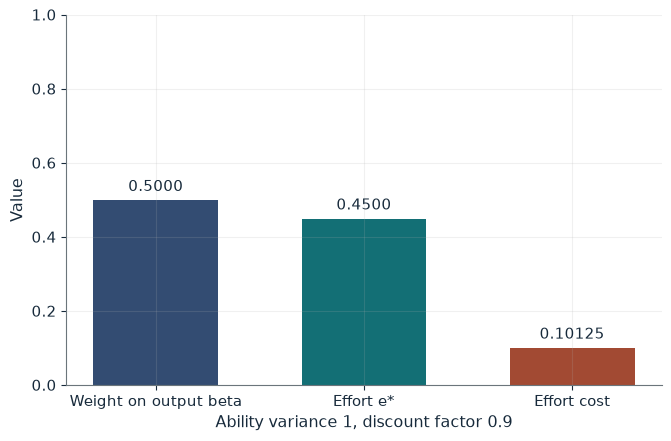

Posterior weight beta  0.5000
Effort e*              0.4500
Effort cost            0.10125

Worked steps:
  1. beta = 1 / (1 + 1) = 0.5000
  2. e* = 0.9 x 0.5000 = 0.4500
  3. Cost = 0.4500 x 0.4500 / 2 = 0.10125

The market puts weight 0.5000 on Elena's output when it updates its view of her ability, so one more unit of effort raises discounted future pay by 0.4500. With cost e^2/2 she sets effort equal to that return: e* = 0.4500, at a cost of 0.10125, with no current bonus at all. Hand check: beta = 1 / (1 + 1) = 0.5000; e* = 0.9 x 0.5000 = 0.4500; Cost = 0.4500 x 0.4500 / 2 = 0.10125.


In [2]:
show(career_picture(var_theta=1.0, delta=0.9))

Change one input, `var_theta`, and hold the others at the book's values:

In [3]:
sweep(career_picture, 'var_theta', [0.3333333333333333, 1.0, 3.0], {'delta': 0.9}, ['Posterior weight beta', 'Effort e*', 'Effort cost'])

var_theta | Posterior weight beta | Effort e* | Effort cost
0.3333333333333333 | 0.2500 | 0.2250 | 0.02531
1.0 | 0.5000 | 0.4500 | 0.10125
3.0 | 0.7500 | 0.6750 | 0.22781


As the market learns (variance 1/3), beta falls to 0.25 and effort to 0.225; more uncertainty (variance 3) raises effort to 0.675.

## 2. Multitask incentive problem: paying for closed tickets

The agent's payoff is

$$u=bx+4y-\frac12(x^2+y^2)-0.5xy$$

so at $b=4$, $x+0.5y=4$ and $y+0.5x=4$. The firm values $x$ at 2 and $y$ at 10. Here the cross term is written $\rho xy$ so it can be set to 0, as the book's counterfactual does.

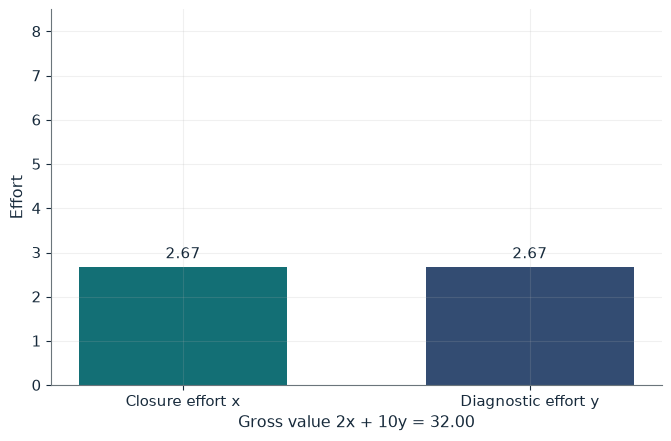

Closure effort x     2.67
Diagnostic effort y  2.67
Gross value          32.00
Change from b = 4    0.00

Worked steps:
  1. x = (4 - 0.5 x 4) / (1 - 0.25) = 2 / 0.75 = 2.6667
  2. y = 4 - 0.5 x 2.6667 = 2.6667
  3. Value = 2 x 2.6667 + 10 x 2.6667 = 5.33 + 26.67 = 32.00

With closure incentive 4 and cross-task parameter 0.5, the agent closes 2.67 units and diagnoses 2.67, for gross value 32.00. This is the starting incentive b = 4. Hand check: x = (4 - 0.5 x 4) / (1 - 0.25) = 2 / 0.75 = 2.6667; y = 4 - 0.5 x 2.6667 = 2.6667; Value = 2 x 2.6667 + 10 x 2.6667 = 5.33 + 26.67 = 32.00.


In [4]:
show(multitask_picture(b=4, rho=0.5))

Change one input, `b`, and hold the others at the book's values:

In [5]:
sweep(multitask_picture, 'b', [4, 5, 6, 7], {'rho': 0.5}, ['Closure effort x', 'Diagnostic effort y', 'Gross value'])

b | Closure effort x | Diagnostic effort y | Gross value
4 | 2.67 | 2.67 | 32.00
5 | 4.00 | 2.00 | 28.00
6 | 5.33 | 1.33 | 24.00
7 | 6.67 | 0.67 | 20.00


With connected tasks, value falls from 32 to 20 as b rises to 7. With `rho=0.0`, x = b, y = 4 and value rises from 48 to 54.

## 3. Linear-contract robustness: noise flattens the slope

With variance 16 and $r=0.05$,

$$S(b)=b-\frac12b^2-\frac12(0.05)(16)b^2=b-0.9b^2$$

so $b^*=1/1.8$.

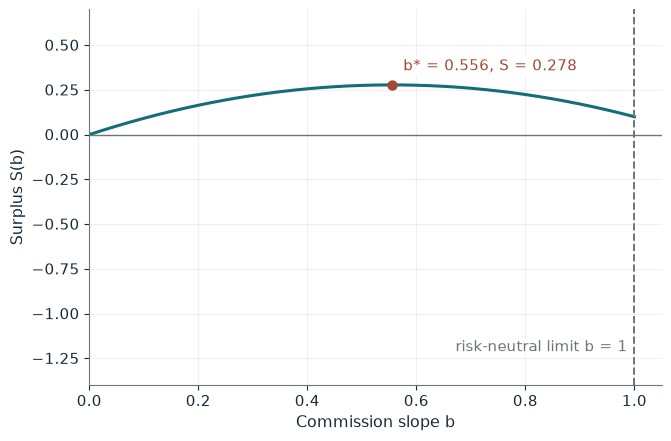

Optimal slope b*  0.556
Effort cost       0.154
Risk premium      0.123
Surplus           0.278

Worked steps:
  1. S(b) = b - 0.5b^2 - 0.5 x 0.05 x 16 b^2 = b - 0.9000b^2
  2. b* = 1 / (2 x 0.9000) = 0.5556
  3. Effort cost = 0.5 x 0.55556^2 = 0.1543
  4. Risk premium = 0.5 x 0.05 x 16 x 0.55556^2 = 0.1235
  5. Surplus = b*/2 = 0.5556 / 2 = 0.2778

With residual variance 16 and risk aversion 0.05, the risk premium is 0.5 x 0.80 x b^2, so the best slope is 0.556, below the risk-neutral slope of 1. Effort costs 0.154, the risk premium is 0.123 and surplus is 0.278. Hand check: S(b) = b - 0.5b^2 - 0.5 x 0.05 x 16 b^2 = b - 0.9000b^2; b* = 1 / (2 x 0.9000) = 0.5556; Effort cost = 0.5 x 0.55556^2 = 0.1543; Risk premium = 0.5 x 0.05 x 16 x 0.55556^2 = 0.1235; Surplus = b*/2 = 0.5556 / 2 = 0.2778.


In [6]:
show(slope_picture(var=16, r=0.05))

Change one input, `var`, and hold the others at the book's values:

In [7]:
sweep(slope_picture, 'var', [4, 16, 36], {'r': 0.05}, ['Optimal slope b*', 'Risk premium', 'Surplus'])

var | Optimal slope b* | Risk premium | Surplus
4 | 0.833 | 0.069 | 0.417
16 | 0.556 | 0.123 | 0.278
36 | 0.357 | 0.115 | 0.179


Exact surplus at the optimum is b*/2 = 0.278; the book's rounded parts sum to 0.279, a gap it attributes to rounding. Variance 4 raises the slope to 0.833.

## 4. Ratchet effect: hiding capacity from a buyer who ratchets

Revealing earns 15 now and 4 later; concealing earns 5 now and 20 later. With $\delta=0.9$,

$$15+0.9(4)=18.6, \qquad 5+0.9(20)=23$$

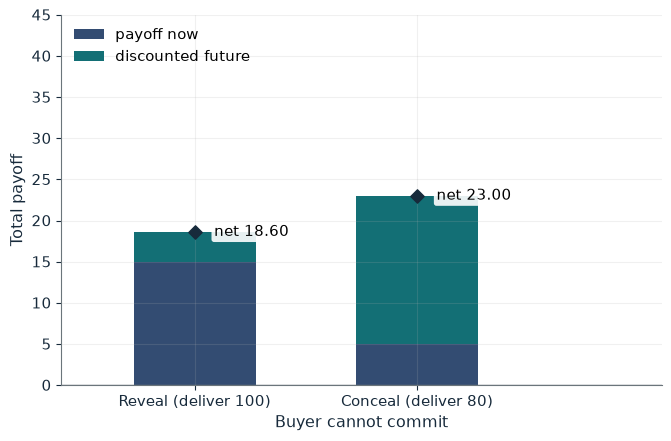

Reveal   18.60
Conceal  23.00
Choice   conceal

Worked steps:
  1. Reveal = 15 + 0.9 x 4 = 18.60
  2. Conceal = 5 + 0.9 x 20 = 23.00
  3. Future gain from concealing = 0.9 x 16 = 14.40 > 10 given up now; concealing wins only when delta > 10 / 16 = 0.625

Revealing capacity is worth 18.60 and concealing 23.00, so the supplier chooses to conceal. The buyer would ratchet the target, so concealing gives up 10 now to keep 14.40 of discounted future payoff; that is worth it. Hand check: Reveal = 15 + 0.9 x 4 = 18.60; Conceal = 5 + 0.9 x 20 = 23.00; Future gain from concealing = 0.9 x 16 = 14.40 > 10 given up now; concealing wins only when delta > 10 / 16 = 0.625.


In [8]:
show(ratchet_picture(delta=0.9, commit='no'))

Change one input, `delta`, and hold the others at the book's values:

In [9]:
sweep(ratchet_picture, 'delta', [0.5, 0.6, 0.9], {'commit': 'no'}, ['Reveal', 'Conceal', 'Choice'])

delta | Reveal | Conceal | Choice
0.5 | 17.00 | 15.00 | reveal
0.6 | 17.40 | 17.00 | reveal
0.9 | 18.60 | 23.00 | conceal


Concealing pays only when delta x 16 exceeds 10, so above 0.625. With commitment (`commit='yes'`) revealing gives 15 + 0.9 x 20 = 33 and always wins.

## Your numbers

Replace the inputs below with your own and run the cell. Every function above accepts any value in the range its section describes.

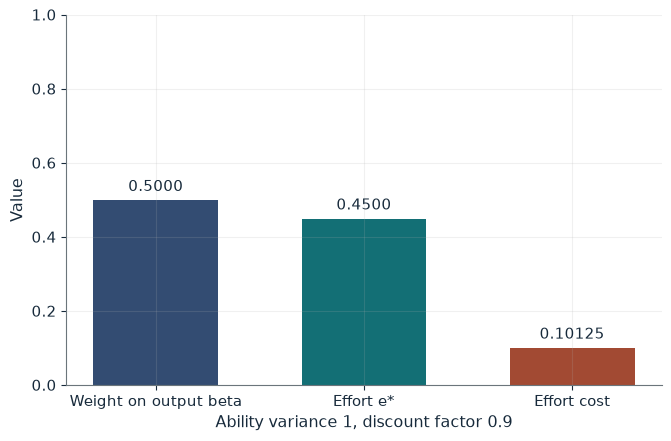

Posterior weight beta  0.5000
Effort e*              0.4500
Effort cost            0.10125

Worked steps:
  1. beta = 1 / (1 + 1) = 0.5000
  2. e* = 0.9 x 0.5000 = 0.4500
  3. Cost = 0.4500 x 0.4500 / 2 = 0.10125

The market puts weight 0.5000 on Elena's output when it updates its view of her ability, so one more unit of effort raises discounted future pay by 0.4500. With cost e^2/2 she sets effort equal to that return: e* = 0.4500, at a cost of 0.10125, with no current bonus at all. Hand check: beta = 1 / (1 + 1) = 0.5000; e* = 0.9 x 0.5000 = 0.4500; Cost = 0.4500 x 0.4500 / 2 = 0.10125.


In [10]:
show(career_picture(var_theta=1.0, delta=0.9))

## Practice

**1.** With ability variance 3 and delta 0.9, what are beta and effort?

<details><summary>Answer</summary>

beta = 3 / 4 = 0.75 and e* = 0.9 x 0.75 = 0.675.

</details>

**2.** In the multitask example with rho = 0.5 and b = 5, what are x, y and gross value?

<details><summary>Answer</summary>

x = (5 - 2) / 0.75 = 4, y = 4 - 0.5 x 4 = 2, value 2 x 4 + 10 x 2 = 28.

</details>

**3.** At variance 36 and r = 0.05, what are the optimal slope and surplus?

<details><summary>Answer</summary>

S = b - (0.5 + 0.9)b^2 = b - 1.4b^2, so b* = 1 / 2.8 = 0.357 and surplus 0.357 / 2 = 0.179.

</details>